<a href="https://colab.research.google.com/github/MatheusMacagnan/AulaPythonFaculdade/blob/Matheus_Alves_Macagnan/aula_14/Matheus_Macagnan_Aula_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Atividade 1

In [ ]:
import requests
from getpass import getpass

# API utilizada: WeatherAPI
# Documentação: https://www.weatherapi.com/docs/

# Solicita a chave da API sem exibi-la na tela
API_KEY = getpass("Digite sua API KEY: ")

# Lista com 10 cidades brasileiras
cidades = [
    "Curitiba",
    "São Paulo",
    "Rio de Janeiro",
    "Belo Horizonte",
    "Porto Alegre",
    "Florianópolis",
    "Salvador",
    "Brasília",
    "Recife",
    "Manaus"
]

# Endpoint da WeatherAPI
URL = "https://api.weatherapi.com/v1/current.json"

Digite sua API KEY: ··········


In [ ]:
# Lista para armazenar os resultados
resultados = []

# Percorre todas as cidades
for cidade in cidades:

    # Parâmetros enviados para a API
    parametros = {
        "key": API_KEY,
        "q": cidade,
        "lang": "pt"
    }

    try:
        # Realiza a consulta à API
        resposta = requests.get(
            URL,
            params=parametros,
            timeout=10
        )

        # Exibe o código de status HTTP
        print(f"\nCidade: {cidade}")
        print(f"Status HTTP: {resposta.status_code}")

        # Verifica se ocorreu algum erro HTTP
        resposta.raise_for_status()

        # Converte a resposta para dicionário Python
        dados = resposta.json()

        # Armazena os dados na lista
        resultados.append(dados)

    except requests.exceptions.HTTPError as erro:
        print(f"Erro HTTP ao consultar {cidade}: {erro}")

    except requests.exceptions.Timeout:
        print(f"Tempo limite excedido ao consultar {cidade}.")

    except requests.exceptions.ConnectionError:
        print(f"Falha de conexão ao consultar {cidade}.")

    except requests.exceptions.RequestException as erro:
        print(f"Erro na requisição de {cidade}: {erro}")


Cidade: Curitiba
Status HTTP: 200

Cidade: São Paulo
Status HTTP: 200

Cidade: Rio de Janeiro
Status HTTP: 200

Cidade: Belo Horizonte
Status HTTP: 200

Cidade: Porto Alegre
Status HTTP: 200

Cidade: Florianópolis
Status HTTP: 200

Cidade: Salvador
Status HTTP: 200

Cidade: Brasília
Status HTTP: 200

Cidade: Recife
Status HTTP: 200

Cidade: Manaus
Status HTTP: 200


In [ ]:
# Exibe os resultados coletados
print("\n========== RESULTADOS CLIMÁTICOS ==========")

for dados in resultados:

    # Inspeciona as principais chaves do dicionário
    print("\nChaves principais:", dados.keys())

    # Obtém o nome da cidade
    cidade = dados["location"]["name"]

    # Obtém a temperatura atual em Celsius
    temperatura = dados["current"]["temp_c"]

    # Obtém a condição do tempo
    condicao = dados["current"]["condition"]["text"]

    # Exibe as informações
    print(f"Cidade: {cidade}")
    print(f"Temperatura: {temperatura} °C")
    print(f"Condição do tempo: {condicao}")

    print("-------------------------------------------")


========== RESULTADOS CLIMÁTICOS ==========

Chaves principais: dict_keys(['location', 'current'])
Cidade: Curitiba
Temperatura: 20.8 °C
Condição do tempo: Chuva passageira fraca
-------------------------------------------

Chaves principais: dict_keys(['location', 'current'])
Cidade: Sao Paulo
Temperatura: 23.8 °C
Condição do tempo: Chuva irregular nas proximidades
-------------------------------------------

Chaves principais: dict_keys(['location', 'current'])
Cidade: Rio De Janeiro
Temperatura: 24.4 °C
Condição do tempo: Chuva fraca
-------------------------------------------

Chaves principais: dict_keys(['location', 'current'])
Cidade: Belo Horizonte
Temperatura: 22.9 °C
Condição do tempo: Chuva passageira fraca
-------------------------------------------

Chaves principais: dict_keys(['location', 'current'])
Cidade: Porto Alegre
Temperatura: 25.7 °C
Condição do tempo: Garoa fraca
-------------------------------------------

Chaves principais: dict_keys(['location', 'current'])


Atividade 2

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Lista para armazenar os dados organizados
dados_clima = []

# Percorre os resultados da API
for dados in resultados:

    registro = {
        "Cidade": dados["location"]["name"],
        "Regiao": dados["location"]["region"],
        "Temperatura": dados["current"]["temp_c"],
        "Sensacao_Termica": dados["current"]["feelslike_c"],
        "Umidade": dados["current"]["humidity"],
        "Vento": dados["current"]["wind_kph"],
        "Condicao": dados["current"]["condition"]["text"],
        "Data_Hora": dados["location"]["localtime"]
    }

    dados_clima.append(registro)

# Cria o DataFrame
df = pd.DataFrame(dados_clima)

# Exibe os dados
print(df)

           Cidade             Regiao  Temperatura  Sensacao_Termica  Umidade  \
0        Curitiba             Parana         20.8              23.5       91   
1       Sao Paulo          Sao Paulo         23.8              26.8       81   
2  Rio De Janeiro     Rio de Janeiro         24.4              28.5       88   
3  Belo Horizonte       Minas Gerais         22.9              26.4       85   
4    Porto Alegre  Rio Grande do Sul         25.7              27.3       75   
5   Florianópolis     Santa Catarina         22.2              24.6       93   
6        Salvador              Bahia         26.3              28.7       86   
7        Brasília   Distrito Federal         21.3              23.4       90   
8          Recife         Pernambuco         26.4              28.0       71   
9          Manaus           Amazonas         32.6              35.6       50   

   Vento                          Condicao         Data_Hora  
0    3.6            Chuva passageira fraca  2026-11-18 1

In [ ]:
# Remove registros duplicados
df = df.drop_duplicates()

# Converte a coluna de data e hora
df["Data_Hora"] = pd.to_datetime(df["Data_Hora"])

# Converte as colunas numéricas
df["Temperatura"] = pd.to_numeric(df["Temperatura"])
df["Sensacao_Termica"] = pd.to_numeric(df["Sensacao_Termica"])
df["Umidade"] = pd.to_numeric(df["Umidade"])
df["Vento"] = pd.to_numeric(df["Vento"])

# Exibe os tipos de dados
print("\nTipos de dados:")
print(df.dtypes)

# Exibe o resumo estatístico
print("\nResumo estatístico:")
print(df.describe())

# Exibe a tabela tratada
print("\nDados tratados:")
print(df)


Tipos de dados:
Cidade                      object
Regiao                      object
Temperatura                float64
Sensacao_Termica           float64
Umidade                      int64
Vento                      float64
Condicao                    object
Data_Hora           datetime64[ns]
dtype: object

Resumo estatístico:
       Temperatura  Sensacao_Termica    Umidade      Vento  \
count    10.000000         10.000000  10.000000  10.000000   
mean     24.640000         27.280000  81.000000   8.000000   
min      20.800000         23.400000  50.000000   3.600000   
25%      22.375000         25.050000  76.500000   4.075000   
50%      24.100000         27.050000  85.500000   7.750000   
75%      26.150000         28.375000  89.500000  10.000000   
max      32.600000         35.600000  93.000000  16.200000   
std       3.431618          3.508339  12.961481   4.322037   

                 Data_Hora  
count                   10  
mean   2026-11-18 19:49:00  
min    2026-11-18 18:5

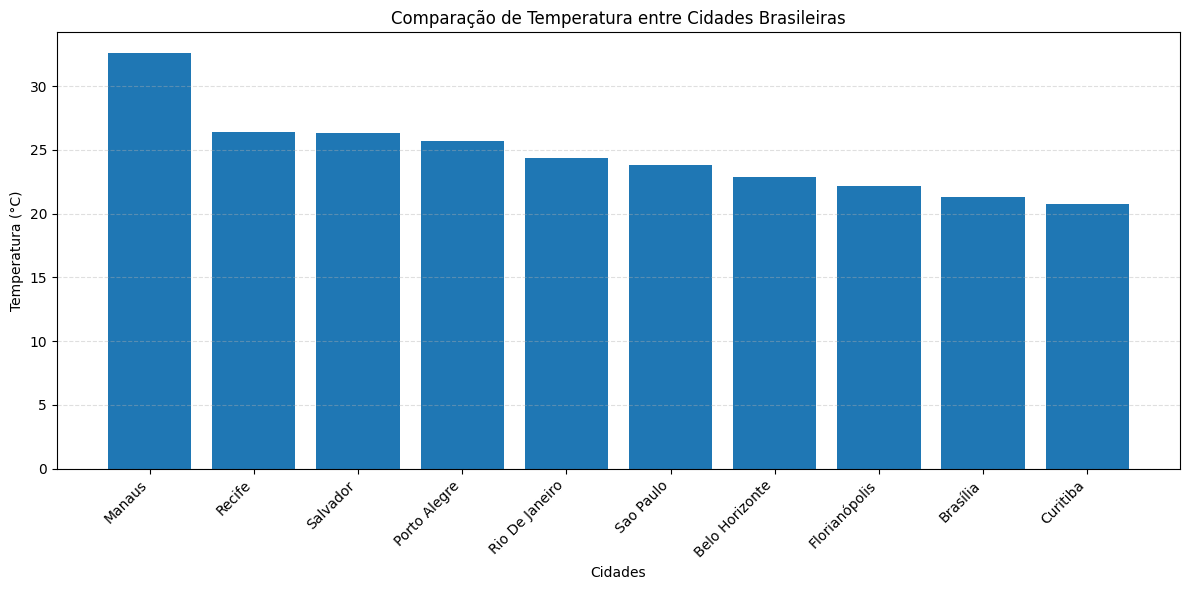


Relatório exportado com sucesso!


In [ ]:
# Ordena as cidades pela temperatura
df_grafico = df.sort_values(
    by="Temperatura",
    ascending=False
)

# Cria o gráfico
plt.figure(figsize=(12, 6))

plt.bar(
    df_grafico["Cidade"],
    df_grafico["Temperatura"]
)

# Configurações visuais
plt.title("Comparação de Temperatura entre Cidades Brasileiras")
plt.xlabel("Cidades")
plt.ylabel("Temperatura (°C)")

plt.xticks(rotation=45, ha="right")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Exibe o gráfico
plt.show()

# Exporta os dados para Excel
df.to_excel("relatorio_climatico.xlsx", index=False)

print("\nRelatório exportado com sucesso!")